# Прогнозирование продаж современными методами (LightGBM)

**Курс:** Прикладной анализ временных рядов (ИТМО). **Практическое задание №2.**

Задача та же, что в задании №1: прогноз дневных продаж 15 товаров магазина
**`STORE_2`** на неделю (7 дней), месяц (30 дней) и квартал (90 дней).
Отличие: вместо классических моделей используется современная -
градиентный бустинг (LightGBM), обученный глобально на всех товарах сразу.

Код находится в пакете `src/sales_forecast`. В ноутбуке только вызовы методов
класса `ModernSalesForecaster`, визуализации и комментарии.


In [1]:
import logging
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sales_forecast import ModernSalesForecaster, SalesForecaster, plotting  # noqa: E402

warnings.filterwarnings("ignore")
logging.getLogger("sales_forecast").setLevel(logging.WARNING)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path.cwd().parent / "data"
STORE = "STORE_2"

## 1. Описание реализованного класса

Для задания №2 добавлены модули поверх инфраструктуры из задания №1:

| Модуль | Назначение |
|---|---|
| `features.py` | сбор панели (date, item): лаги, rolling mean и std, календарь, цена, праздники |
| `boosting.py` | класс `LightGBMGlobalModel`: обучение на pooled panel, рекурсивный прогноз |
| `modern_forecaster.py` | класс **`ModernSalesForecaster`** - фасад с тем же API, что у `SalesForecaster` |

`ModernSalesForecaster` наследует `SalesForecaster`, поэтому предобработка данных,
сплит, метрики и графики те же. Отличие в обучении: LightGBM учится один раз на всех
товарах, а `seasonal_naive` остается как дешевый baseline.

### Основные методы

| Метод | Что делает |
|---|---|
| `load_data()` | читает CSV, собирает `StoreDataset` |
| `fit()` | готовит train и test, обучает LightGBM и baseline, строит прогноз на 90 дней |
| `predict(horizon)` | прогнозы на 7, 30 или 90 дней |
| `evaluate()`, `evaluate_total()`, `summary(metric)` | метрики по товарам и в пуле |
| `backtest(n_folds)` | rolling-origin валидация |
| `feature_importance()` | gain-важность признаков LightGBM |
| `plot_forecast()`, `plot_total_metrics()`, `plot_item_metrics()` | визуализации |

Предобработка: интерполяция закрытого дня (25 декабря), отсечение ведущих нулей у
поздних товаров, лаги (1, 2, 3, 7, 14, 28), rolling окна 7 и 28, календарные признаки,
цена, типы праздников, cashback, categorical `item_id`. Прогноз на 90 шагов -
рекурсивный (каждый день дописывается в историю и идет в лаги следующего).


## 2. Загрузка данных


In [2]:
forecaster = ModernSalesForecaster(STORE, data_dir=DATA_DIR)
dataset = forecaster.load_data()
print(
    f"Период: {dataset.sales.index[0].date()} - {dataset.sales.index[-1].date()}, "
    f"{len(dataset.sales)} дней, {len(dataset.items)} товаров"
)
forecaster.describe_items().round(2)

Период: 2011-01-29 - 2016-01-21, 1819 дней, 15 товаров


,mean,std,zero_share,max,first_sale,mean_price
STORE_2_090,132.09,110.96,0.20,763.0,2011-01-29,1.33
STORE_2_586,70.57,17.89,0.00,151.0,2011-01-29,1.59
STORE_2_252,42.74,16.10,0.00,138.0,2011-01-29,1.52
STORE_2_587,36.80,30.38,0.10,154.0,2011-02-01,2.51
STORE_2_555,30.99,9.62,0.00,76.0,2011-01-29,1.59
STORE_2_681,28.45,25.02,0.08,207.0,2011-01-29,1.10
STORE_2_714,27.06,11.25,0.00,84.0,2011-01-29,1.52
STORE_2_376,19.07,17.18,0.09,166.0,2011-01-29,1.00
STORE_2_524,12.07,11.65,0.19,85.0,2011-01-30,0.99
STORE_2_325,7.65,6.16,0.15,43.0,2011-08-13,1.15


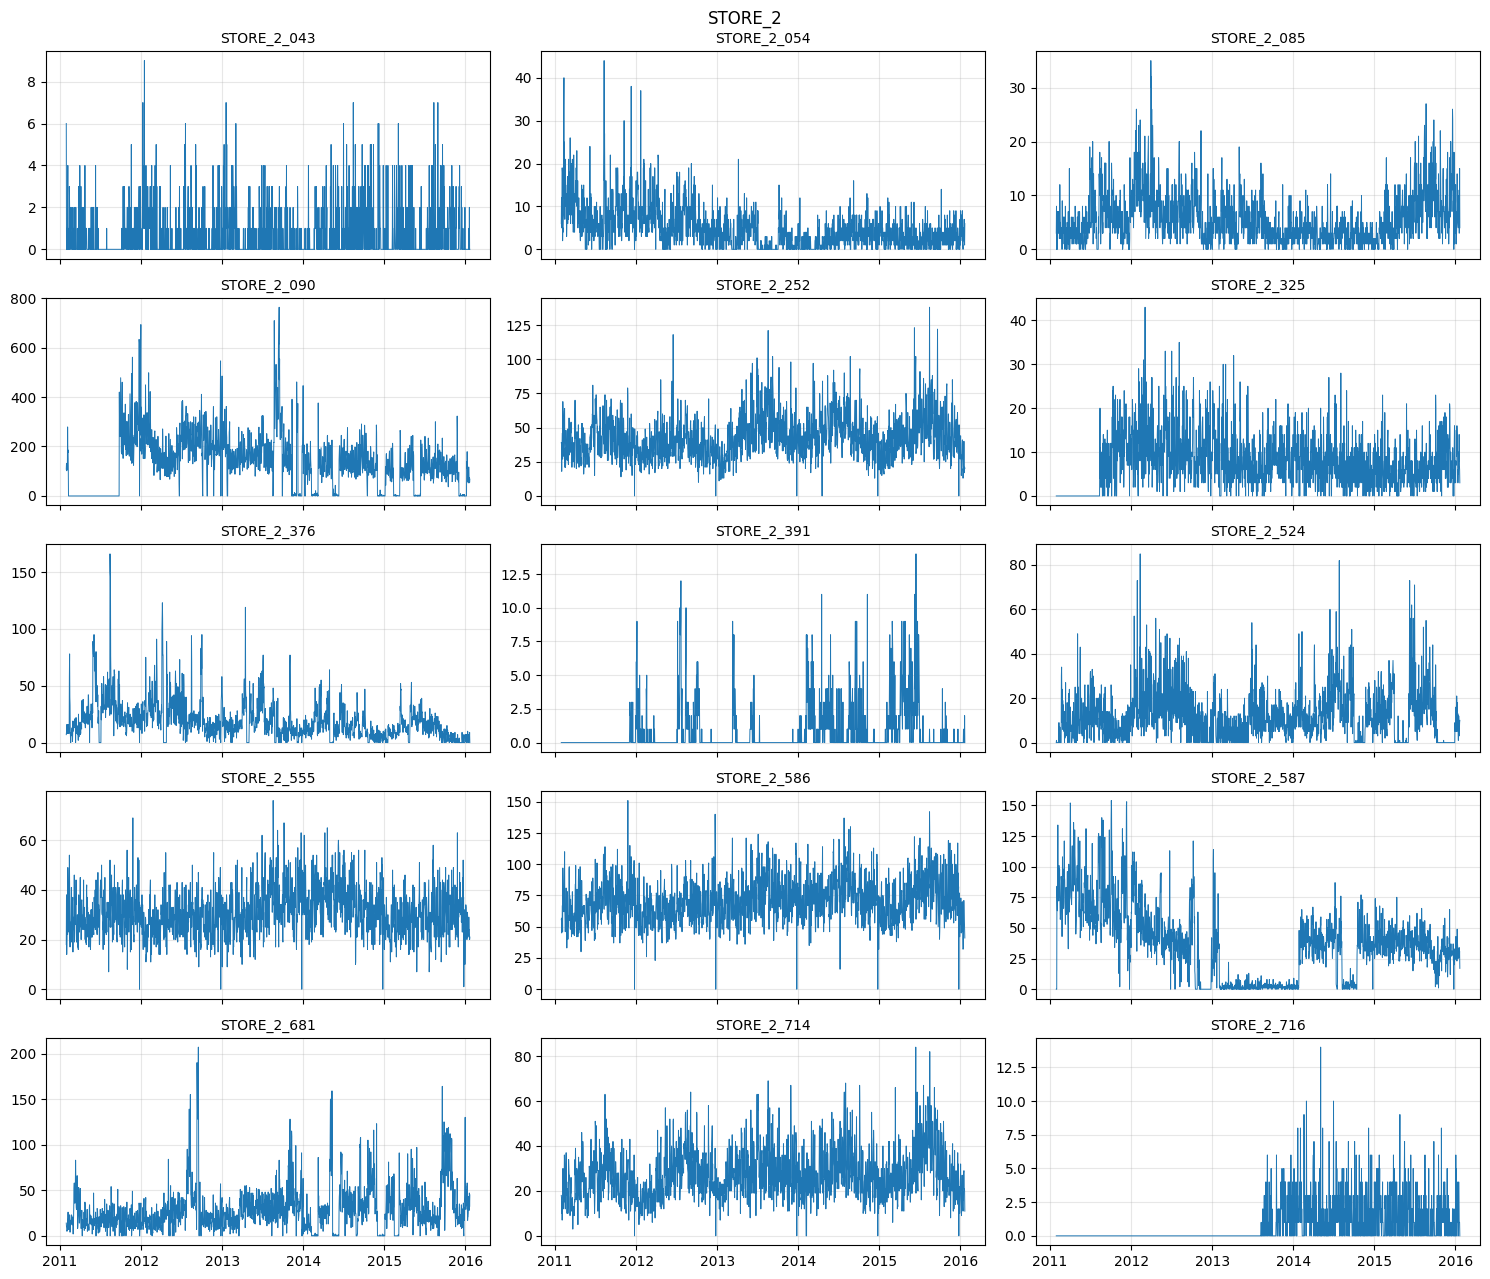

In [3]:
forecaster.plot_items();

## 3. Обучение LightGBM

Тест - последние 90 дней (24.10.2015 - 21.01.2016). Early stopping идет по хвосту
обучающей выборки (последние 90 дней трейна), holdout в подборе числа деревьев
не участвует.


In [4]:
%%time
forecaster.fit();

CPU times: user 2.79 s, sys: 3.71 s, total: 6.5 s
Wall time: 3.4 s


In [5]:
print("best_iteration:", forecaster.lgbm_.best_iteration_)
forecaster.feature_importance(15).round(1)

best_iteration: 227


roll_mean_7     265019.2
lag_1            88053.3
roll_mean_28     57883.5
roll_std_7       31670.0
roll_std_28      13912.8
item_id          10524.8
dow               7546.6
lag_2             6916.6
lag_7             4405.6
cos_doy           4114.3
lag_14            3609.7
lag_28            3519.3
sin_doy           3177.8
sell_price        3061.4
lag_3             2868.1
Name: gain, dtype: float64

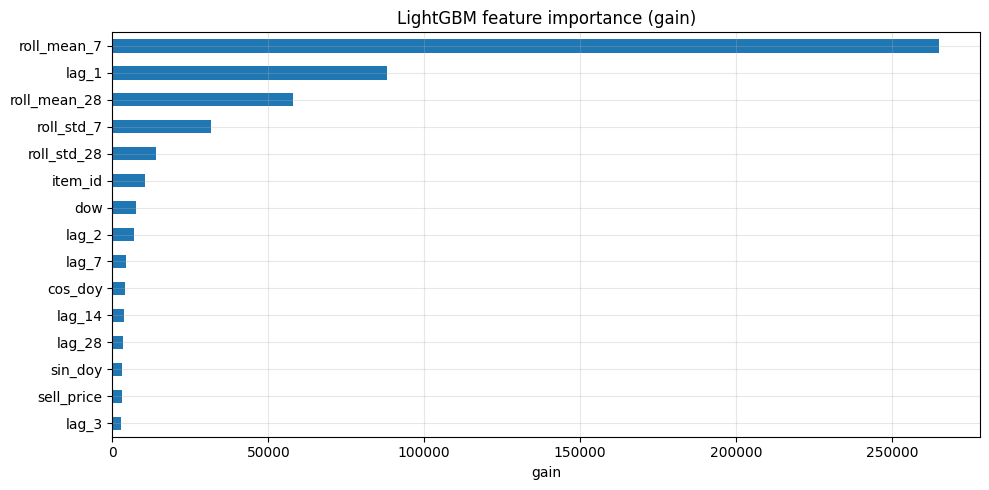

In [6]:
ax = forecaster.feature_importance(15).iloc[::-1].plot.barh(figsize=(10, 5))
ax.set_title("LightGBM feature importance (gain)")
ax.set_xlabel("gain")
plt.tight_layout()

Самые сильные признаки - краткосрочный уровень ряда (`roll_mean_7`, `lag_1`,
`roll_mean_28`). Дальше идут волатильность, `item_id` и день недели. Цена и праздники
дают меньший вклад, но остаются в модели.


## 4. Качество на отложенной выборке

Метрики те же, что в задании №1: MAE, RMSE, WAPE, MASE. MAPE не используем из-за
нулевых продаж. Для ориентира рядом с LightGBM идет seasonal naive, а ниже -
сравнение с SARIMA из задания №1 на том же holdout.


In [7]:
for metric in ["wape", "mase", "mae", "rmse"]:
    print(metric.upper())
    display(forecaster.summary(metric).round(3))

WAPE


horizon,week,month,quarter
model,,,
lightgbm,0.209,0.235,0.373
seasonal_naive,0.250,0.343,0.621


MASE


horizon,week,month,quarter
model,,,
lightgbm,0.548,0.570,0.727
seasonal_naive,0.656,0.831,1.213


MAE


horizon,week,month,quarter
model,,,
lightgbm,6.089,6.333,8.075
seasonal_naive,7.286,9.222,13.466


RMSE


horizon,week,month,quarter
model,,,
lightgbm,9.750,10.994,17.994
seasonal_naive,11.086,17.554,27.753


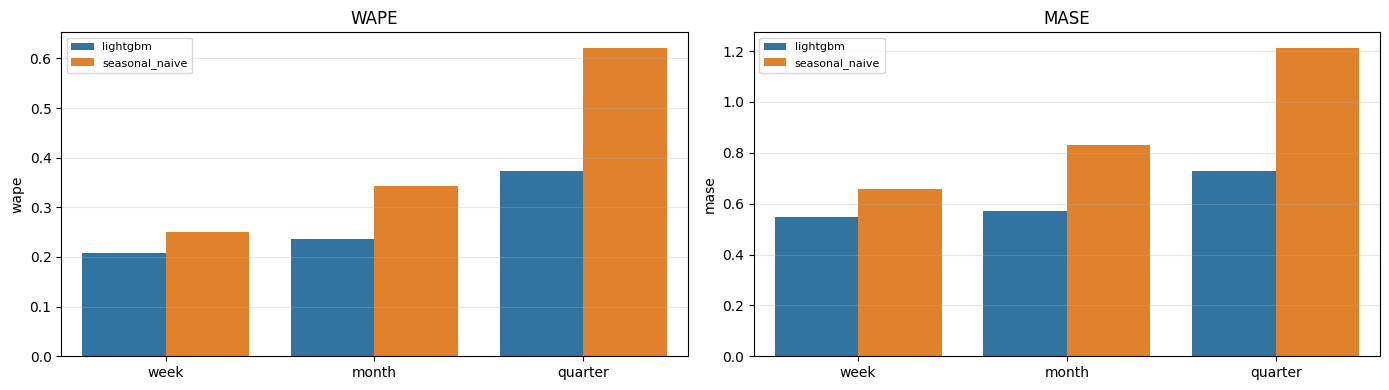

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
forecaster.plot_total_metrics("wape", ax=axes[0])
forecaster.plot_total_metrics("mase", ax=axes[1])
plt.tight_layout()

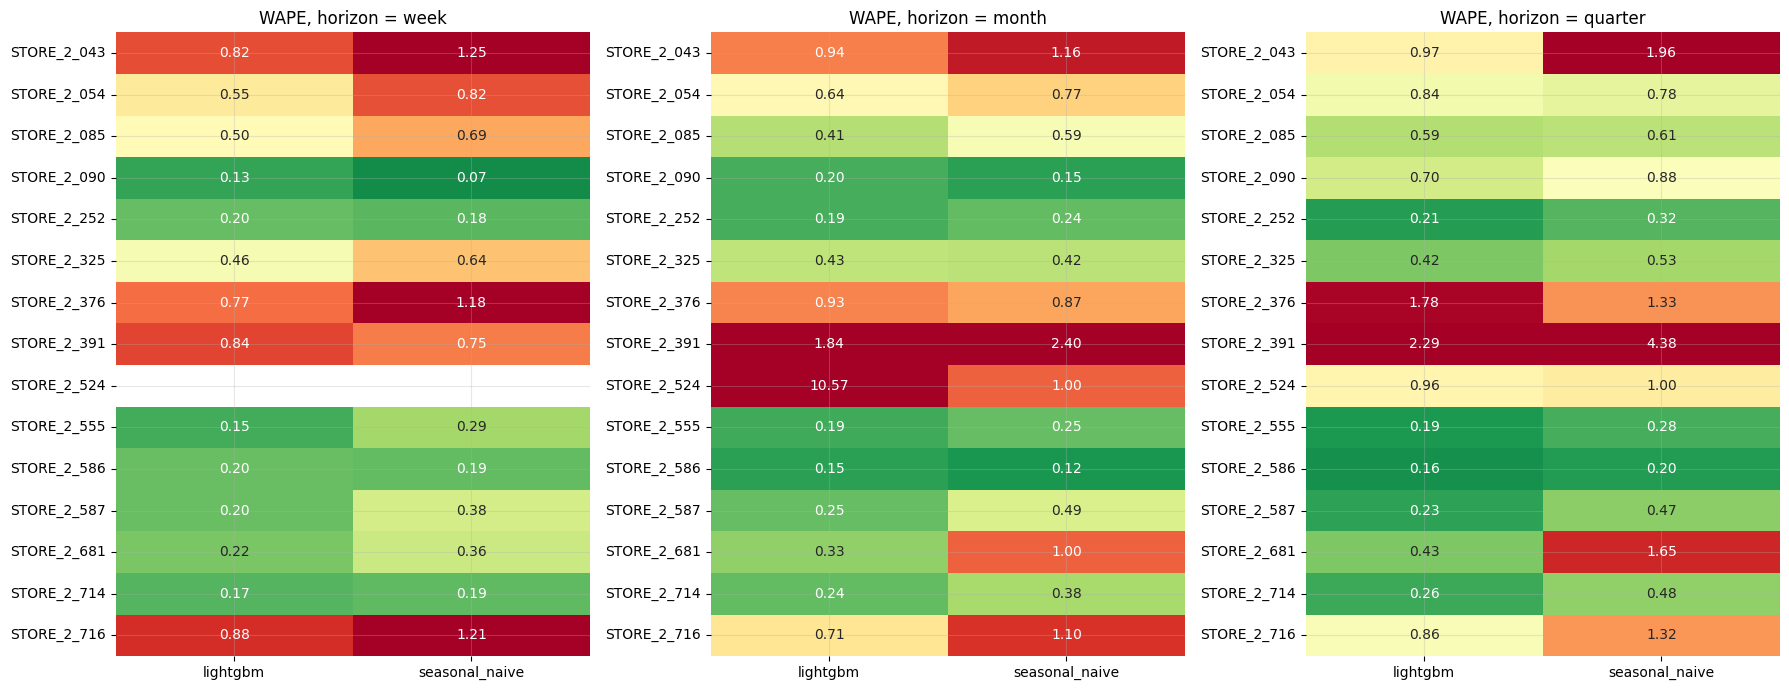

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, horizon in zip(axes, ["week", "month", "quarter"]):
    forecaster.plot_item_metrics("wape", horizon, ax=ax)
plt.tight_layout()

LightGBM заметно лучше naive на всех горизонтах. На квартале MASE меньше 1, то есть
модель устойчиво выигрывает у повторения прошлой недели даже на длинном горизонте,
где рекурсивный прогноз обычно плывет.


### Сравнение с SARIMA (задание №1)

Обучаем SARIMA на том же сплите и смотрим pooled WAPE.


In [10]:
%%time
classical = SalesForecaster(STORE, data_dir=DATA_DIR, models=["sarima"])
classical.load_data()
classical.fit()

comparison = pd.concat(
    {
        "lightgbm": forecaster.summary("wape").loc["lightgbm"],
        "sarima": classical.summary("wape").loc["sarima"],
        "seasonal_naive": forecaster.summary("wape").loc["seasonal_naive"],
    },
    axis=1,
).T
comparison.round(3)

CPU times: user 2min 3s, sys: 1.96 s, total: 2min 5s
Wall time: 2min 7s


horizon,week,month,quarter
lightgbm,0.209,0.235,0.373
sarima,0.164,0.250,0.460
seasonal_naive,0.250,0.343,0.621


На неделе SARIMA чуть точнее (локальная сезонная структура). На месяце модели близки,
на квартале LightGBM заметно лучше: глобальная модель лучше переживает сдвиги уровня
и декабрьское окно за счет общих паттернов по товарам и календарных признаков.


### Визуализация прогнозов


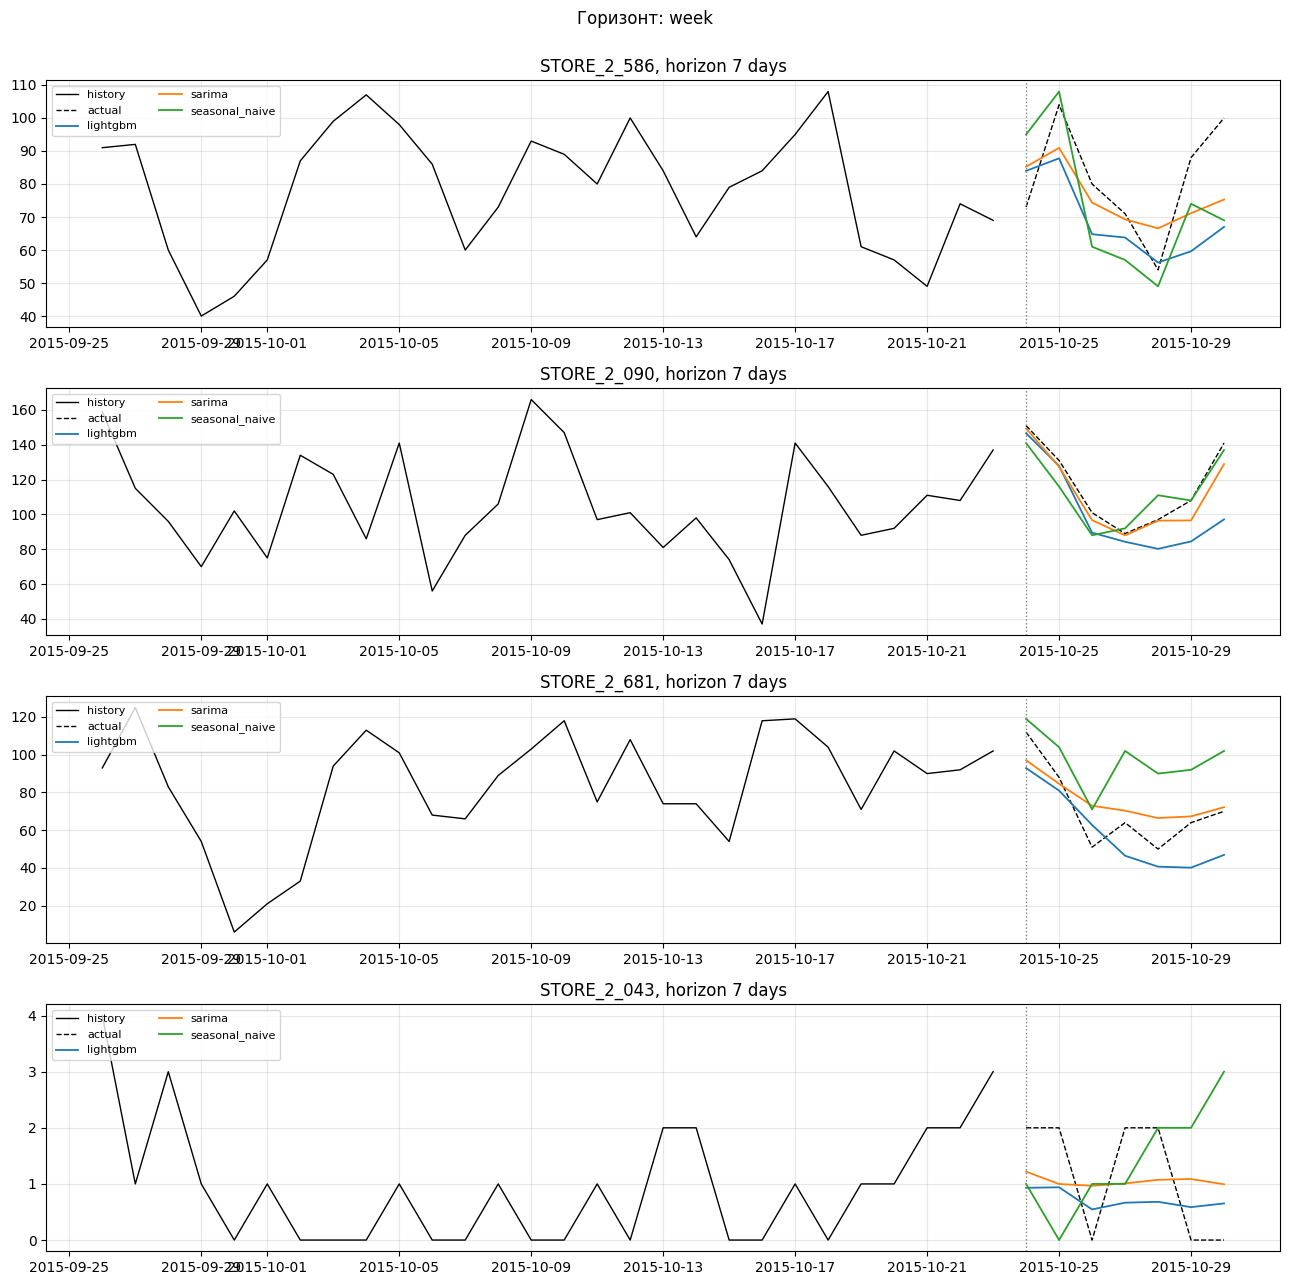

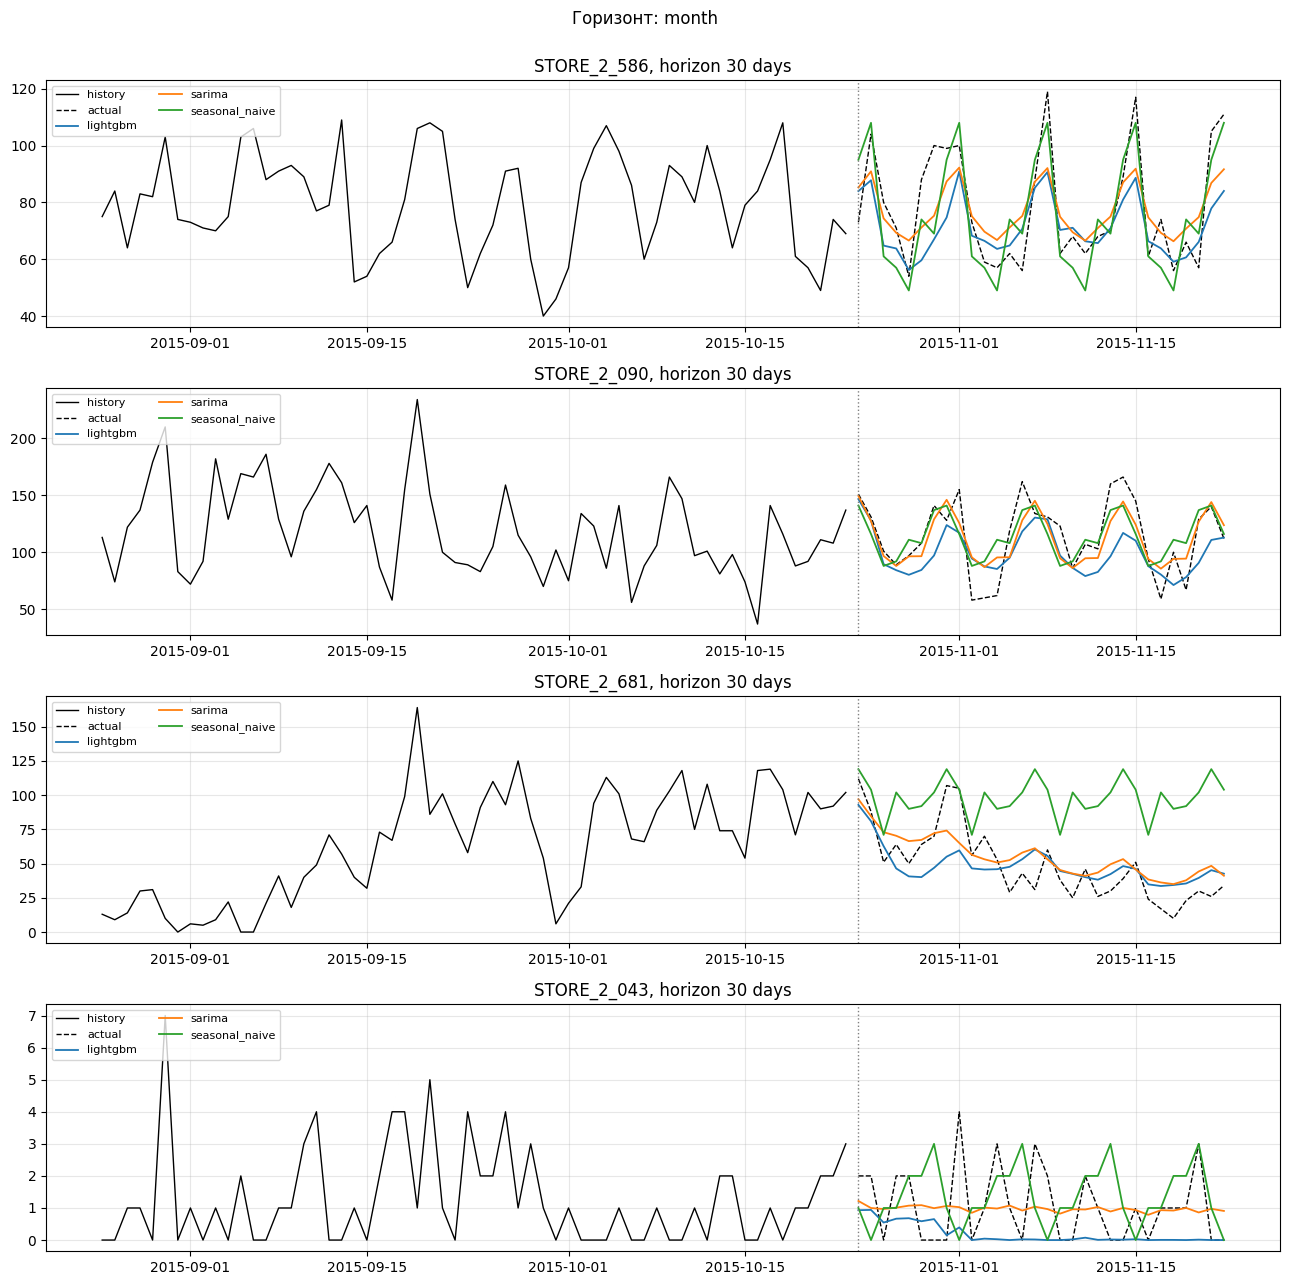

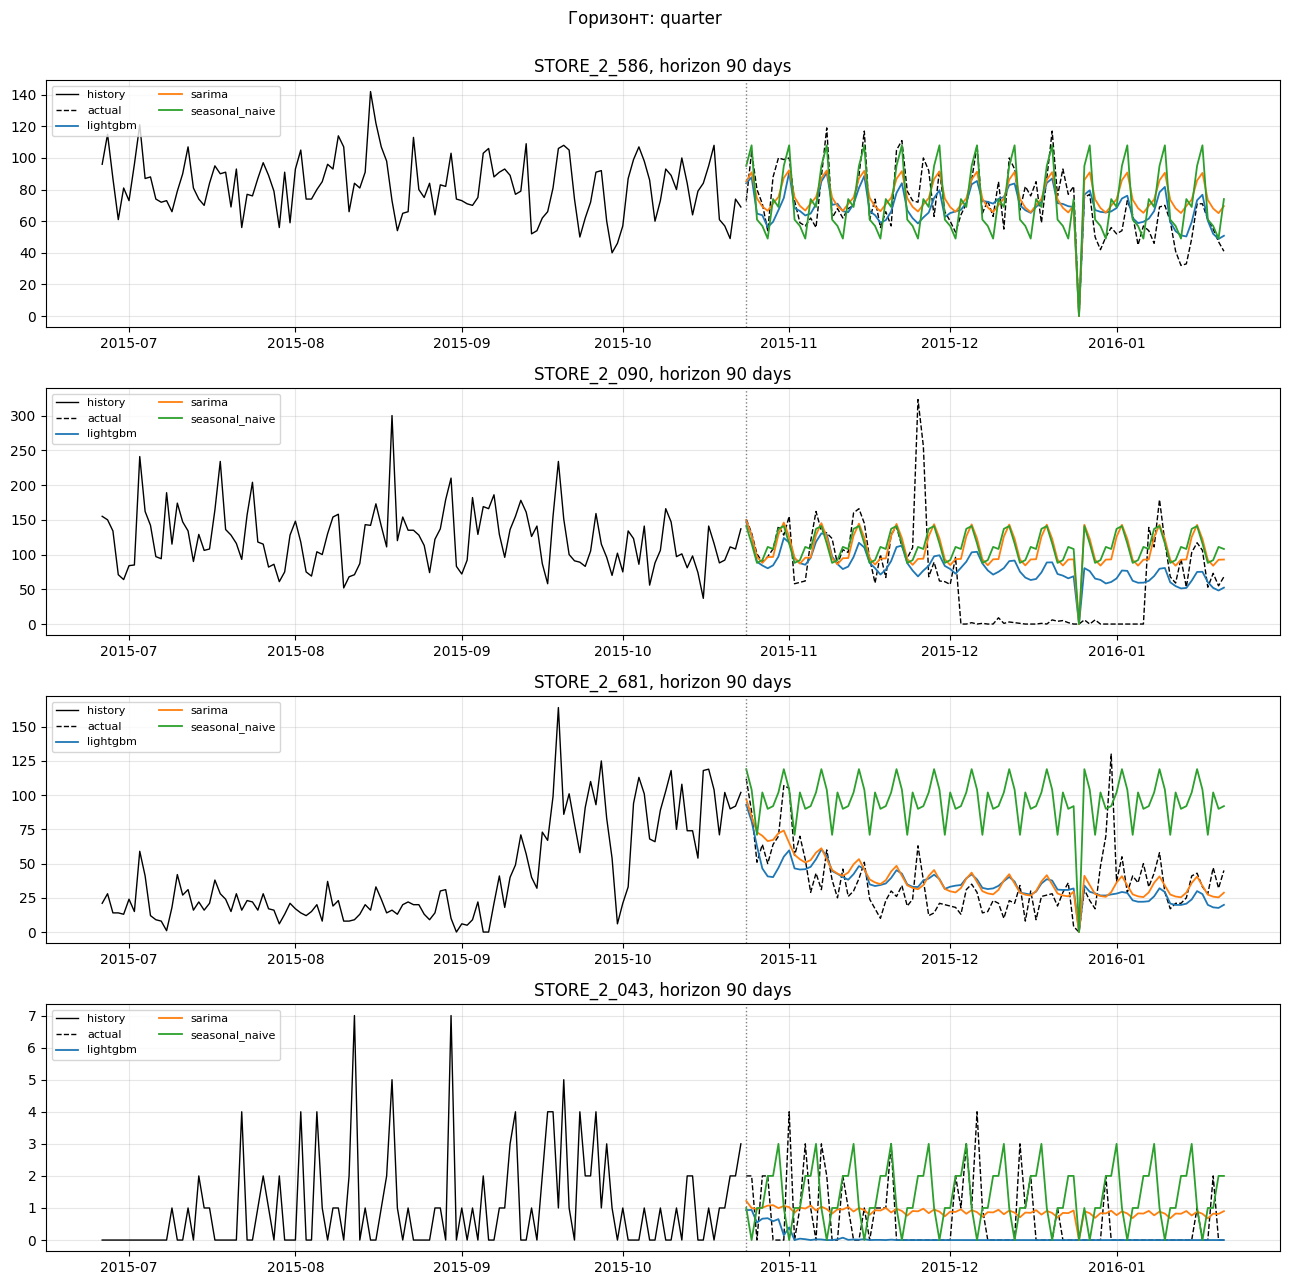

In [11]:
SHOW_ITEMS = ["STORE_2_586", "STORE_2_090", "STORE_2_681", "STORE_2_043"]
for horizon, history in [("week", 28), ("month", 60), ("quarter", 120)]:
    days = forecaster.horizons[horizon]
    fig, axes = plt.subplots(len(SHOW_ITEMS), 1, figsize=(13, 3.2 * len(SHOW_ITEMS)))
    for ax, item in zip(axes, SHOW_ITEMS):
        forecasts = {
            "lightgbm": forecaster.predict(horizon)["lightgbm"][item],
            "sarima": classical.predict(horizon)["sarima"][item],
            "seasonal_naive": forecaster.predict(horizon)["seasonal_naive"][item],
        }
        plotting.plot_forecast(
            history=forecaster.train_[item].iloc[-history:],
            actual=forecaster.test_[item].iloc[:days],
            forecasts=forecasts,
            title=f"{item}, horizon {days} days",
            ax=ax,
        )
    fig.suptitle(f"Горизонт: {horizon}", y=1.0)
    plt.tight_layout()

In [12]:
forecaster.forecast_table("STORE_2_586", "week").round(1)

,actual,lightgbm,seasonal_naive
date,,,
2015-10-24,73.0,84.0,95.0
2015-10-25,104.0,87.8,108.0
2015-10-26,80.0,64.8,61.0
2015-10-27,71.0,63.8,57.0
2015-10-28,54.0,56.2,49.0
2015-10-29,88.0,59.6,74.0
2015-10-30,100.0,67.0,69.0


## 5. Устойчивость: rolling-origin backtest

Три неперекрывающихся окна по 90 дней. Фолд 0 совпадает с holdout выше.


In [13]:
%%time
backtest = forecaster.backtest(n_folds=3)
backtest.groupby("fold")["train_end"].first().dt.date

CPU times: user 10.3 s, sys: 16 s, total: 26.3 s
Wall time: 13.1 s


fold
0    2015-10-23
1    2015-07-25
2    2015-04-26
Name: train_end, dtype: object

In [14]:
print("WAPE, среднее по 3 фолдам")
display(forecaster.backtest_summary(backtest, "wape").round(3))
print("MASE, среднее по 3 фолдам")
display(forecaster.backtest_summary(backtest, "mase").round(3))

WAPE, среднее по 3 фолдам


horizon,week,month,quarter
model,,,
lightgbm,0.237,0.306,0.376
seasonal_naive,0.312,0.374,0.498


MASE, среднее по 3 фолдам


horizon,week,month,quarter
model,,,
lightgbm,0.617,0.750,0.881
seasonal_naive,0.811,0.921,1.144


In [15]:
backtest.pivot_table(
    index=["horizon", "fold"], columns="model", values="wape"
).round(3)

model         lightgbm  seasonal_naive
horizon fold                          
month   0        0.235           0.343
        1        0.263           0.325
        2        0.418           0.455
quarter 0        0.373           0.621
        1        0.330           0.390
        2        0.425           0.484
week    0        0.209           0.250
        1        0.263           0.360
        2        0.239           0.325

На всех фолдах и горизонтах LightGBM лучше seasonal naive. Квартальный WAPE стабильнее,
чем у SARIMA из задания №1 на последнем holdout.


In [16]:
final = (
    forecaster.evaluate_total()
    .query("model == 'lightgbm'")
    .set_index("horizon")
    .loc[["week", "month", "quarter"], ["wape", "mase", "mae", "rmse"]]
    .round(3)
)
final

,wape,mase,mae,rmse
horizon,,,,
week,0.209,0.548,6.089,9.750
month,0.235,0.570,6.333,10.994
quarter,0.373,0.727,8.075,17.994


## 6. Ответы на вопросы

### Какие методы предобработки данных вы использовали? Почему пробовали именно их?

1. Тот же базовый пайплайн, что в задании №1: wide-матрица с регулярным дневным индексом,
   джойн цен и календаря, интерполяция 25 декабря, отсечение ведущих нулей у новых товаров,
   клиппинг прогноза в неотрицательную область и ноль в закрытые дни.
2. Дополнительно для бустинга - табличные признаки без утечки будущего:
   лаги 1, 2, 3, 7, 14, 28, rolling mean и std на окнах 7 и 28 (только по прошлому),
   календарь (dow, month, weekofyear, sin и cos дня года), цена, типы праздников, cashback,
   categorical `item_id`. Такой набор - стандарт для градиентного бустинга на ритейле:
   модель видит и автокорреляцию, и общие календарные эффекты сразу по всем товарам.

### Какие модели пробовали? Почему пробовали именно их?

Основная модель - **LightGBM** (global recursive). Причины выбора:
быстрое обучение, хорошая работа с табличными признаками и категориальным `item_id`,
устойчивость на прерывистых рядах за счет обучения на pooled panel.
Рядом оставлен **seasonal naive** как baseline и масштаб для MASE.
Для внешней точки сравнения на том же holdout обучена **SARIMA** из задания №1.

Нейросеть не брали: для 15 коротких дневных рядов бустинг обычно дает сопоставимое или
лучшее качество при меньшем риске переобучения и проще объясняется в отчете.

### Как вы проверяете качество модели? На каких данных? Какие метрики используете? Чем обусловлен выбор именно этих метрик?

Holdout - последние 90 дней. Метрики на префиксах прогноза: 7, 30, 90 дней.
Дополнительно rolling-origin backtest на 3 фолдах.
Метрики: MAE, RMSE, WAPE, MASE. WAPE корректно работает при нулях, MASE сразу показывает
выигрыш относительно naive. MAPE не используем.

### Какой подход из испробованных самый оптимальный с точки зрения качества прогнозирования?

Для современного подхода - **глобальный LightGBM** с лагами и календарными признаками.
Он лучше naive на всех горизонтах и фолдах. Относительно SARIMA: на неделе SARIMA
точнее, на квартале LightGBM заметно лучше и намного быстрее в обучении.
Если нужен один рабочий метод на все горизонты, разумный выбор - LightGBM.

### Какое итоговое качество модели на тестовом датасете?

Итоговые метрики LightGBM на holdout приведены в таблице выше.
Среднее WAPE по 3 фолдам backtest: около 0.237, 0.306, 0.376 (неделя, месяц, квартал).
